# Projet Leyenda - Livrable 3
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Après avoir réalisé les deux premiers livrables, l'objectif est de créer un réseau de neurones qui génère des légendes pour des photographies, en s'appuyant sur le dataset dataset MS COCO. Il sera divisé en 2 partie la premiere via un CNN et la deuxieme sera le RNN pour le captionning. Nous utilisons un modèle pré-entrainé: *Inception V3*

Détail du ***Livrable 3:***
- L'architecture schématique complète du réseau utilisé pour le captioning explicitant le type de CNN utilisé pour les prétraitements.
- Un petit descriptif sur le pré-traitements de images et du texte.
- Le code explicitant l'architecture du CNN et du RNN utilisés dans le captioning.
- L'évolution sous forme de courbes des performances du réseau pendant l'entrainement. Affichage de quelques exemples pour les tests.

## Importation des librairies

In [57]:
%pip requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: unknown command "requirements.txt"



In [58]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input


In [64]:
import json
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input

IMG_SIZE = 300
THRESHOLD = 0.001
MAX_WORDS = 20

CLASSIFIER_PATH = Path("workflow/models/classifier.keras")
DENOISER_PATH   = Path("workflow/models/denoiser.keras")
CKPT_DIR        = Path("checkpoints_gru")

DOSSIER = Path("workflow/img")


## GRU

In [65]:
#GRU

class CNN_Encoder(tf.keras.Model):
    def __init__(self, embedding_dim):
        super().__init__()
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        x = self.fc(x)        
        x = tf.nn.relu(x)
        return x


class BahdanauAttention(tf.keras.layers.Layer):
    def __init__(self, units):
        super().__init__()

        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        

        hidden_with_time_axis = tf.expand_dims(hidden, axis=1)

        
        attention_hidden = tf.nn.tanh(
            self.W1(features) + self.W2(hidden_with_time_axis)
        )

        
        scores = self.V(attention_hidden)

        
        attention_weights = tf.nn.softmax(scores, axis=1)

        
        context_vector = tf.reduce_sum(
            attention_weights * features,
            axis=1,
        )

        return context_vector, attention_weights

class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size,
                 attention_units=512, dropout_rate=0.3, gru_dropout=0.0):
        super().__init__()
        self.units = units
        self.embedding = layers.Embedding(vocab_size, embedding_dim)
        self.attention = BahdanauAttention(attention_units)
        self.gru = layers.GRU(units,
                              #dropout=gru_dropout,
                              return_sequences=True,
                              return_state=True)
        self.fc1 = layers.Dense(units)
        #self.dropout = layers.Dropout(dropout_rate)
        self.fc2 = layers.Dense(vocab_size)

    def call(self, word_id, features, hidden, training=False):
        context_vector, attention_weights = self.attention(features, hidden)

        x = self.embedding(word_id)
        context = tf.expand_dims(context_vector, axis=1)
        x = tf.concat([context, x], axis=-1)

        output, hidden = self.gru(x, initial_state=hidden, training=training)

        x = self.fc1(output)
        x = tf.reshape(x, (-1, x.shape[2]))
        #x = self.dropout(x, training=training)
        logits = self.fc2(x)

        return logits, hidden, attention_weights

    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))

In [66]:
# 1- Classifieur photo / pas photo
classifier = tf.keras.models.load_model(CLASSIFIER_PATH, compile=False)

# 2- Denoiser
denoiser = tf.keras.models.load_model(DENOISER_PATH, compile=False)

# 3- Captioning
config = json.loads((CKPT_DIR / "config.json").read_text())
tokenizer = tokenizer_from_json((CKPT_DIR / "tokenizer.json").read_text(encoding="utf-8"))
CAPTION_SIZE = tuple(config["image_size"])
start_token_id = config["start_token_id"]
end_token_id = config["end_token_id"]

inception = InceptionV3(weights="imagenet", include_top=False, input_shape=(*CAPTION_SIZE, 3))
inception.trainable = False
inputs = Input(shape=(*CAPTION_SIZE, 3))
image_encoder = Model(inputs, inception(inputs, training=False))

encoder = CNN_Encoder(config["embedding_dim"])
decoder = RNN_Decoder(config["embedding_dim"], config["rnn_units"], config["vocab_size"])

# Passage factice pour créer les poids
dummy = encoder(tf.zeros((1, 64, 2048)))
decoder(tf.constant([[start_token_id]]), dummy, decoder.reset_state(1))

# Plante si un poids n'est pas trouvé (au lieu d'échouer en silence)
tf.train.Checkpoint(encoder=encoder, decoder=decoder).read(
    str(CKPT_DIR / "best")
).assert_existing_objects_matched()

print("Modèles chargés")


Modèles chargés


In [67]:
def load_image(path):
    img = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)) / 255.0
    return img[None, ...]                                   # (1, 300, 300, 3) dans [0, 1]


def generate_caption(image):
    x = tf.image.resize(image, CAPTION_SIZE)                 # 300 -> 299
    x = preprocess_input(x * 255.0)
    features = tf.reshape(image_encoder(x, training=False), (1, 64, 2048))
    encoded = encoder(features)

    hidden = decoder.reset_state(1)
    word_id = tf.constant([[start_token_id]])
    words = []
    for _ in range(MAX_WORDS):
        logits, hidden, _ = decoder(word_id, encoded, hidden)
        scores = logits[0].numpy()
        scores[[0, 1, start_token_id]] = -1e9                 # bloque pad, unk, startseq
        predicted_id = int(np.argmax(scores))
        if predicted_id == end_token_id:
            break
        words.append(tokenizer.index_word.get(predicted_id, ""))
        word_id = tf.constant([[predicted_id]])
    return " ".join(words)


--- 1359045.jpeg ---


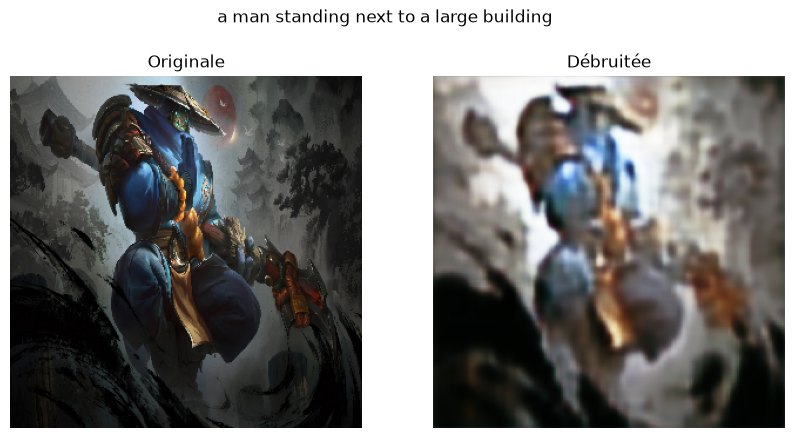

--- 20250418_161552.jpg ---


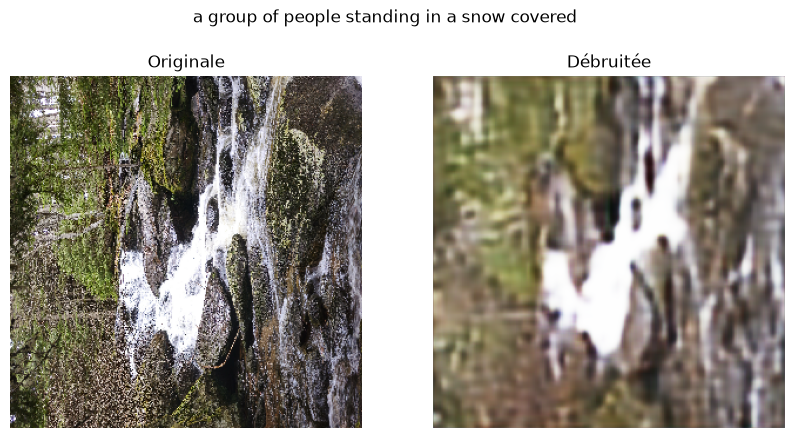

--- Capture d'écran 2025-04-21 184451.png ---


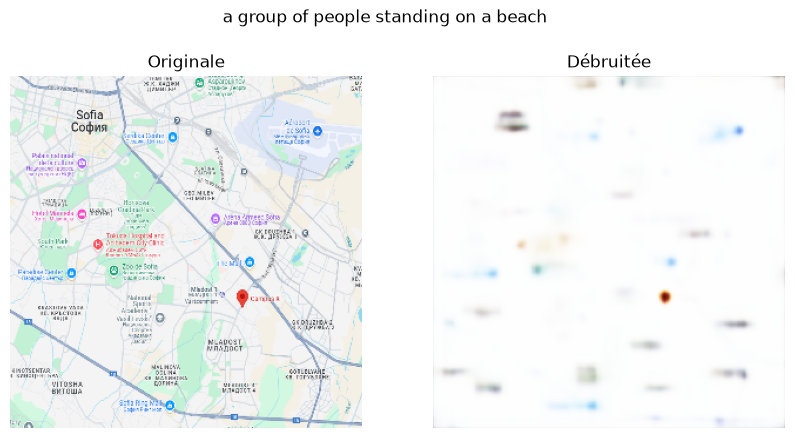

--- COCO_train2014_000000000025.jpg ---


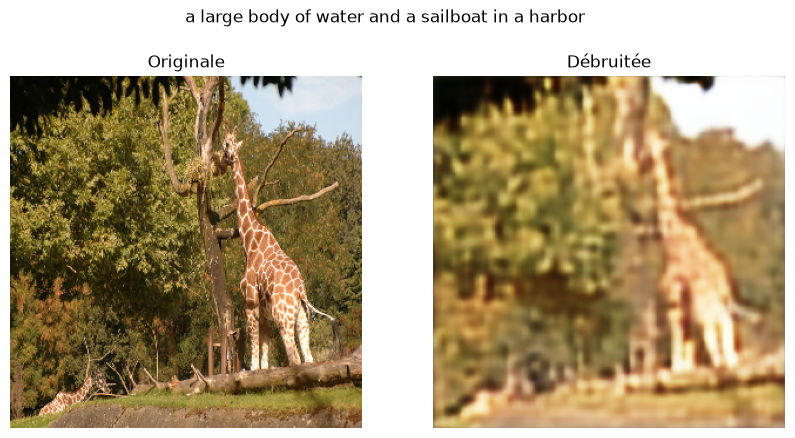

--- image.png ---


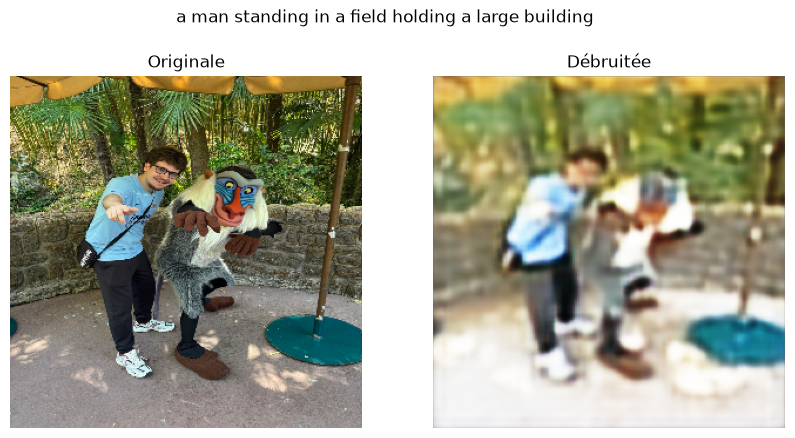

--- IMG_3940.JPG ---


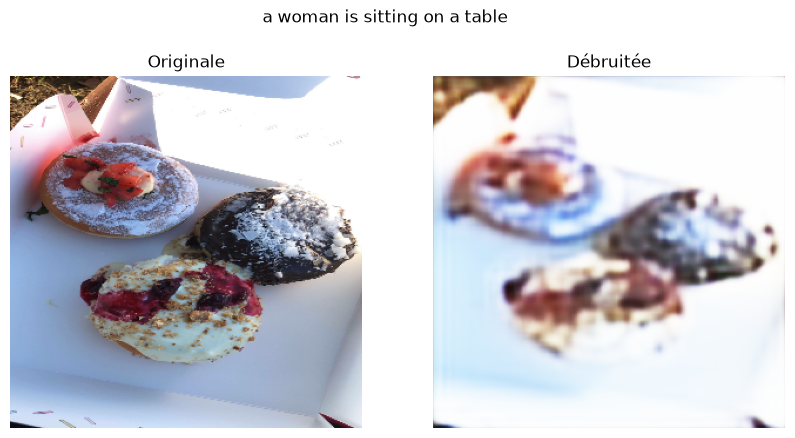

--- wallpaper_dying_light_2_01_1920x1080.jpeg ---


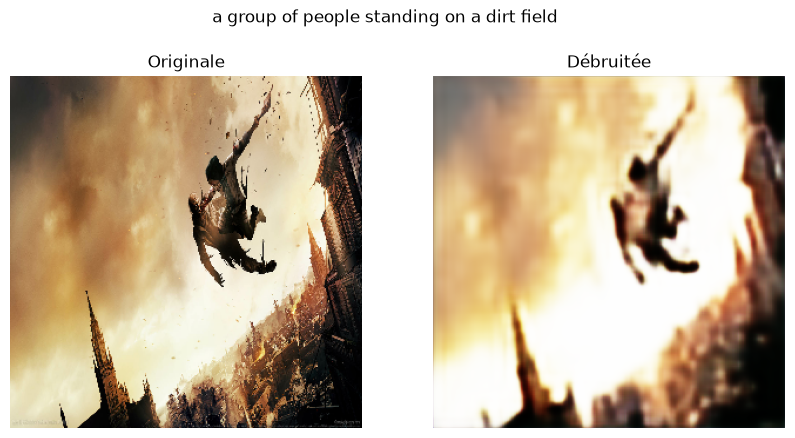


7 photo(s) légendée(s) sur 7 document(s)


In [68]:
def pipeline(path):
    image = load_image(path)

    # 1- Photo ou pas ?
    prob = float(classifier.predict(image, verbose=0)[0][0])
    if prob < THRESHOLD:
        print(f"Pas une photo (p={prob:.2f}) : arrêt.")
        return None

    # 2- Denoising
    clean = np.clip(denoiser.predict(image, verbose=0), 0, 1)

    # 3- Captioning
    caption = generate_caption(clean)

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(image[0]); ax[0].set_title("Originale")
    ax[1].imshow(clean[0]); ax[1].set_title("Débruitée")
    for a in ax: a.axis("off")
    plt.suptitle(caption)
    plt.show()
    return caption

resultats = {}
for path in sorted(DOSSIER.glob("*")):
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue
    print(f"--- {path.name} ---")
    resultats[path.name] = pipeline(path)   # None si ce n'est pas une photo

photos = {k: v for k, v in resultats.items() if v is not None}
print(f"\n{len(photos)} photo(s) légendée(s) sur {len(resultats)} document(s)")
